# Time Series Datasets — Exploratory Data Analysis

**Objective:** Load, validate, and visualise the four 15-minute interval time series datasets (`TS0277`, `TS3423`, `TS3449`, `TS4011`) in `3-time-series/data/` to inspect their temporal coverage, data quality, value distributions, seasonality, diurnal cycles, and cross-series relationships.

## 1. Setup & Data Loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Support running from either PKE/ or PKE/3-time-series/
PROJECT_DIR = Path("./3-time-series") if Path("./3-time-series/src").exists() else Path(".")
if str(PROJECT_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR.resolve()))

DATA_PATH = PROJECT_DIR / "data"

import src.data, src.visualisations

datasets = src.data.read_datasets(str(DATA_PATH))
print(f"Loaded {len(datasets)} datasets from {DATA_PATH.resolve()}")

summary_rows = []
for df in datasets:
    s = df["value"]
    summary_rows.append({
        "dataset": df.attrs["name"],
        "rows": len(df),
        "start": df.index.min(),
        "end": df.index.max(),
        "nulls": int(s.isna().sum()),
        "dup_timestamps": int(df.index.duplicated().sum()),
        "min": round(s.min(), 3),
        "p25": round(s.quantile(0.25), 3),
        "median": round(s.median(), 3),
        "p75": round(s.quantile(0.75), 3),
        "max": round(s.max(), 3),
        "mean": round(s.mean(), 3),
        "std": round(s.std(), 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

Loaded 4 datasets from C:\Users\alex3\Projects\AI sem 1\sem-2\PKE\3-time-series\data


,dataset,rows,start,end,nulls,dup_timestamps,min,p25,median,p75,max,mean,std
0,TS0277,175296,2001-01-01,2005-12-31 23:45:00,0,20,0.0,34.65,51.65,172.800,241.10,94.171,71.205
1,TS3423,175296,2001-01-01,2005-12-31 23:45:00,0,20,0.0,23.00,47.50,72.500,101.00,48.539,24.124
2,TS3449,139488,2002-01-09,2005-12-31 23:45:00,0,16,0.0,7.70,14.90,39.900,102.05,23.919,18.764
3,TS4011,70080,2001-01-01,2002-12-31 23:45:00,0,8,0.0,3.11,6.73,25.862,46.25,12.913,12.599


**Initial Schema & Coverage Notes:**
- Each `.csv.gz` file is headerless with two fields: a 15-minute `timestamp` and a numeric `value`.
- None of the four series contain missing (`NaN`) values, though each series has a small number of duplicate timestamps (`20` in `TS0277` and `TS3423`, `16` in `TS3449`, and `8` in `TS4011`) and differing temporal spans (`2001–2005` for `TS0277`/`TS3423`, `2002-01-09–2005` for `TS3449`, and `2001–2002` for `TS4011`).

## 2. Full Time Series Overview

Let's sneak a peek at the raw data:

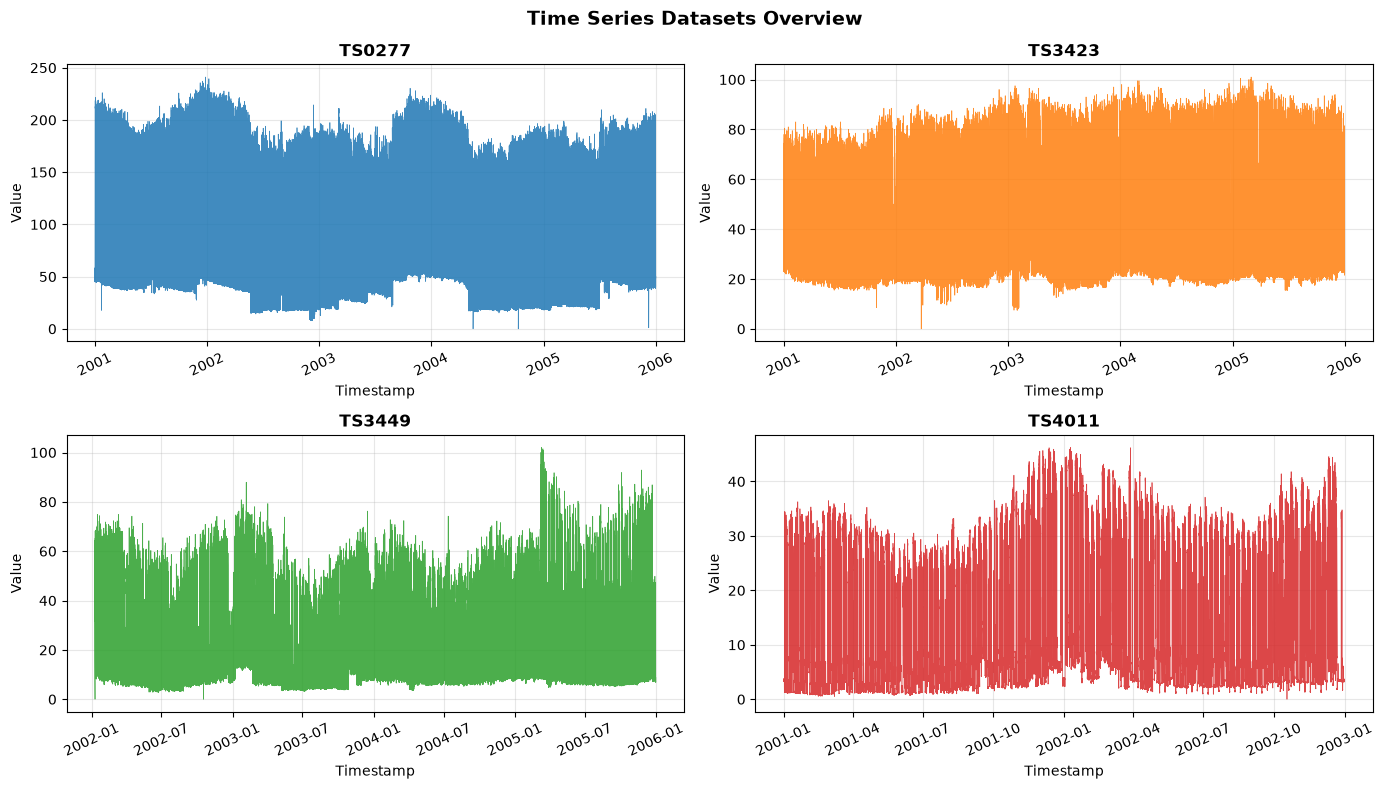

In [2]:
src.visualisations.visualise_datasets(datasets)

**Overview Observations:**
- Plotting all four series side-by-side highlights substantial scale differences (`TS0277` reaches `241.1`, `TS3423` and `TS3449` peak around `101–102`, and `TS4011` stays below `46.25`) as well as differing observation windows.
- Because 15-minute samples across 2–5 years (70k–175k points) are dense, the sections below examine temporal gaps, distributions, monthly seasonality, diurnal cycles, and a short 2-week zoom.

## 3. Temporal Integrity & DST Transitions

In [3]:
for df in datasets:
    name = df.attrs["name"]
    diffs = df.index.to_series().diff()
    irregular = diffs[diffs.notna() & (diffs != pd.Timedelta(minutes=15))]
    print(f"=== {name} (irregular step counts) ===")
    print(irregular.value_counts().to_dict())
    print("Sample irregular transitions:")
    print(irregular.head(4).to_string())
    print()

=== TS0277 (irregular step counts) ===
{Timedelta('0 days 01:15:00'): 5, Timedelta('-1 days +23:15:00'): 5}
Sample irregular transitions:
timestamp
2001-03-25 03:00:00     0 days 01:15:00
2001-10-28 02:00:00   -1 days +23:15:00
2002-03-31 03:00:00     0 days 01:15:00
2002-10-27 02:00:00   -1 days +23:15:00

=== TS3423 (irregular step counts) ===
{Timedelta('0 days 01:15:00'): 5, Timedelta('-1 days +23:15:00'): 5}
Sample irregular transitions:
timestamp
2001-03-25 03:00:00     0 days 01:15:00
2001-10-28 02:00:00   -1 days +23:15:00
2002-03-31 03:00:00     0 days 01:15:00
2002-10-27 02:00:00   -1 days +23:15:00

=== TS3449 (irregular step counts) ===
{Timedelta('0 days 01:15:00'): 4, Timedelta('-1 days +23:15:00'): 4}
Sample irregular transitions:
timestamp
2002-03-31 03:00:00     0 days 01:15:00
2002-10-27 02:00:00   -1 days +23:15:00
2003-03-30 03:00:00     0 days 01:15:00
2003-10-26 02:00:00   -1 days +23:15:00

=== TS4011 (irregular step counts) ===
{Timedelta('0 days 01:15:00'): 2, 

**Temporal Integrity Findings:**
- Irregular step sizes are exclusively `+1h15m` (`0 days 01:15:00`) and `-45m` (`-1 days +23:15:00`), corresponding to spring-forward (1 missing hour = 4 intervals) and fall-back (1 repeated hour = 4 duplicate 15-minute timestamps per year) Daylight Saving Time transitions in local timestamps.
- Before fitting time-series models or aligning series on timestamps, duplicate DST timestamps should be resolved (e.g., averaged or disambiguated with timezone offsets).

## 4. Value Distributions & Outliers

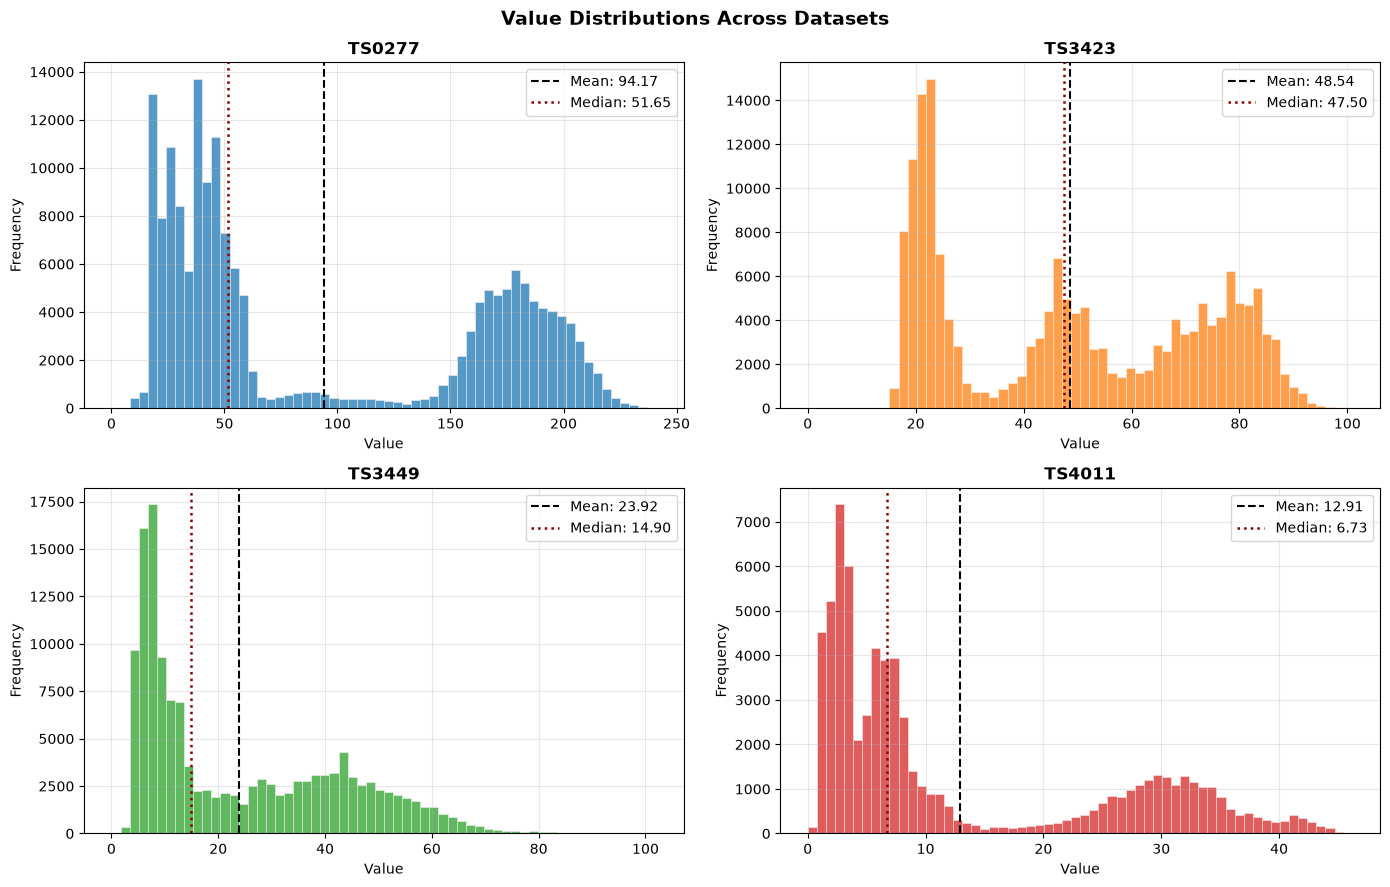

,dataset,iqr,lower_fence,upper_fence,iqr_outliers,outlier_pct,zero_pct
0,TS0277,138.150,-172.575,380.025,0,0.00,0.01
1,TS3423,49.500,-51.250,146.750,0,0.00,0.00
2,TS3449,32.200,-40.600,88.200,76,0.05,0.03
3,TS4011,22.752,-31.019,59.991,0,0.00,0.00


In [4]:
src.visualisations.series_distributions(datasets)

**Distribution & Outlier Notes:**
- Compare the histograms against mean/median markers to see right-skewness (`TS0277`, `TS3449`, `TS4011`, where mean substantially exceeds median) versus more symmetric spread (`TS3423`, mean `48.54` vs. median `47.50`).
- The IQR summary table quantifies tail points exceeding `Q3 + 1.5 * IQR` and exact zero-value prevalence across each series.

## 5. Seasonality, Diurnal Cycles & Short-Term Zoom

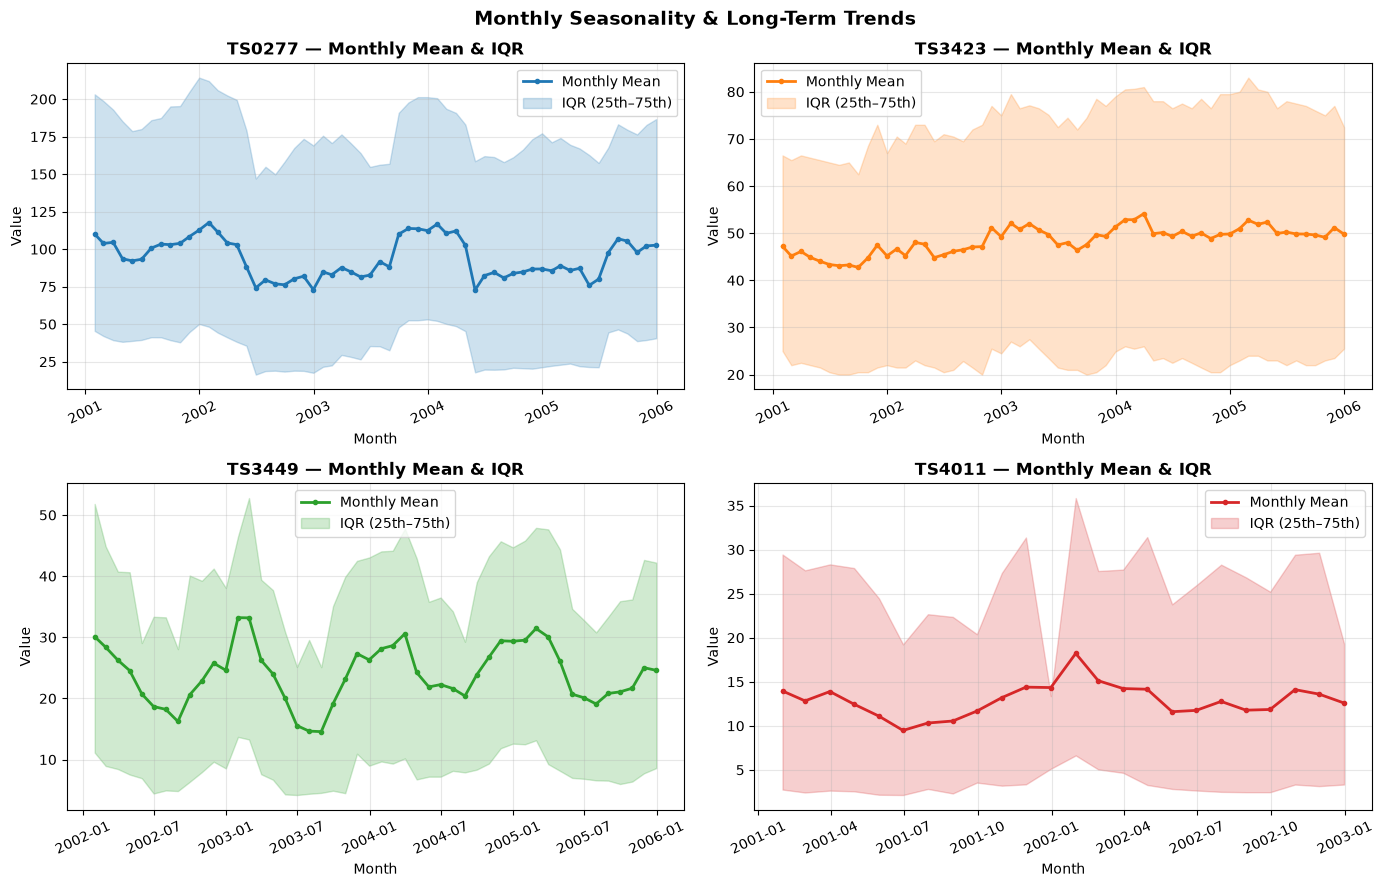

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for idx, (ax, df) in enumerate(zip(axes.flat, datasets)):
    name = df.attrs["name"]
    color = src.visualisations.DEFAULT_CMAP(idx % 10)
    monthly = df["value"].resample("ME").agg(["mean", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
    monthly.columns = ["mean", "p25", "p75"]

    ax.plot(monthly.index, monthly["mean"], color=color, linewidth=2, marker="o", markersize=3, label="Monthly Mean")
    ax.fill_between(monthly.index, monthly["p25"], monthly["p75"], color=color, alpha=0.22, label="IQR (25th–75th)")
    ax.set_title(f"{name} — Monthly Mean & IQR", fontsize=12, fontweight="bold")
    ax.set_xlabel("Month")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=25)

fig.suptitle("Monthly Seasonality & Long-Term Trends", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

If we try to zoom specific weeks aligned across years (e.g. the first week of the year), we will notice the same patterns as on this plot: weekly time series go up or down as tho overall distribution mass goes up or dow on this plot. See Zoomed-In plots below.

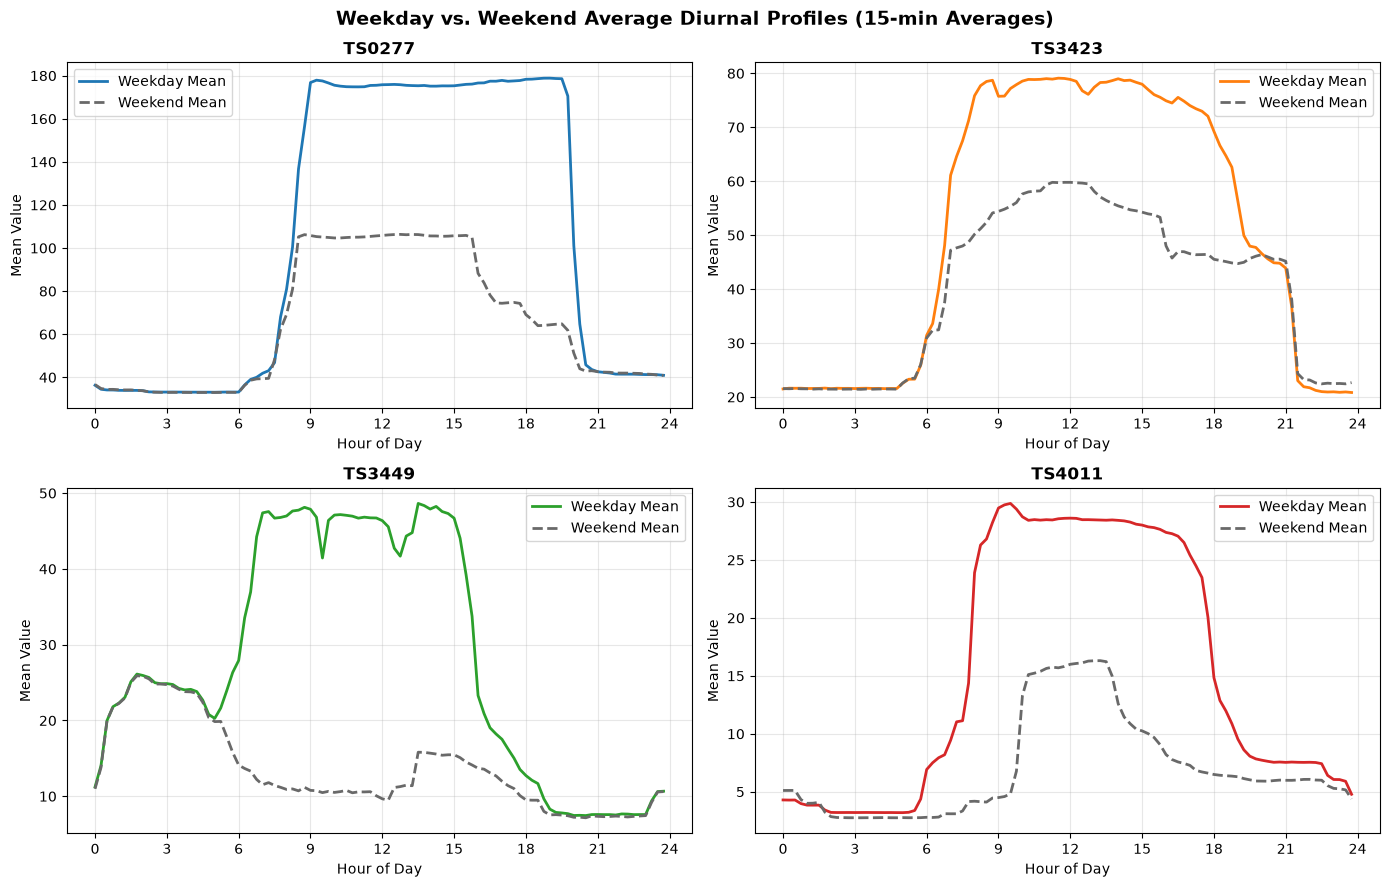

In [6]:
src.visualisations.diurnal_profiles(datasets)

Distribution of weekly energy consumption during one week across different years (dates are aligned):

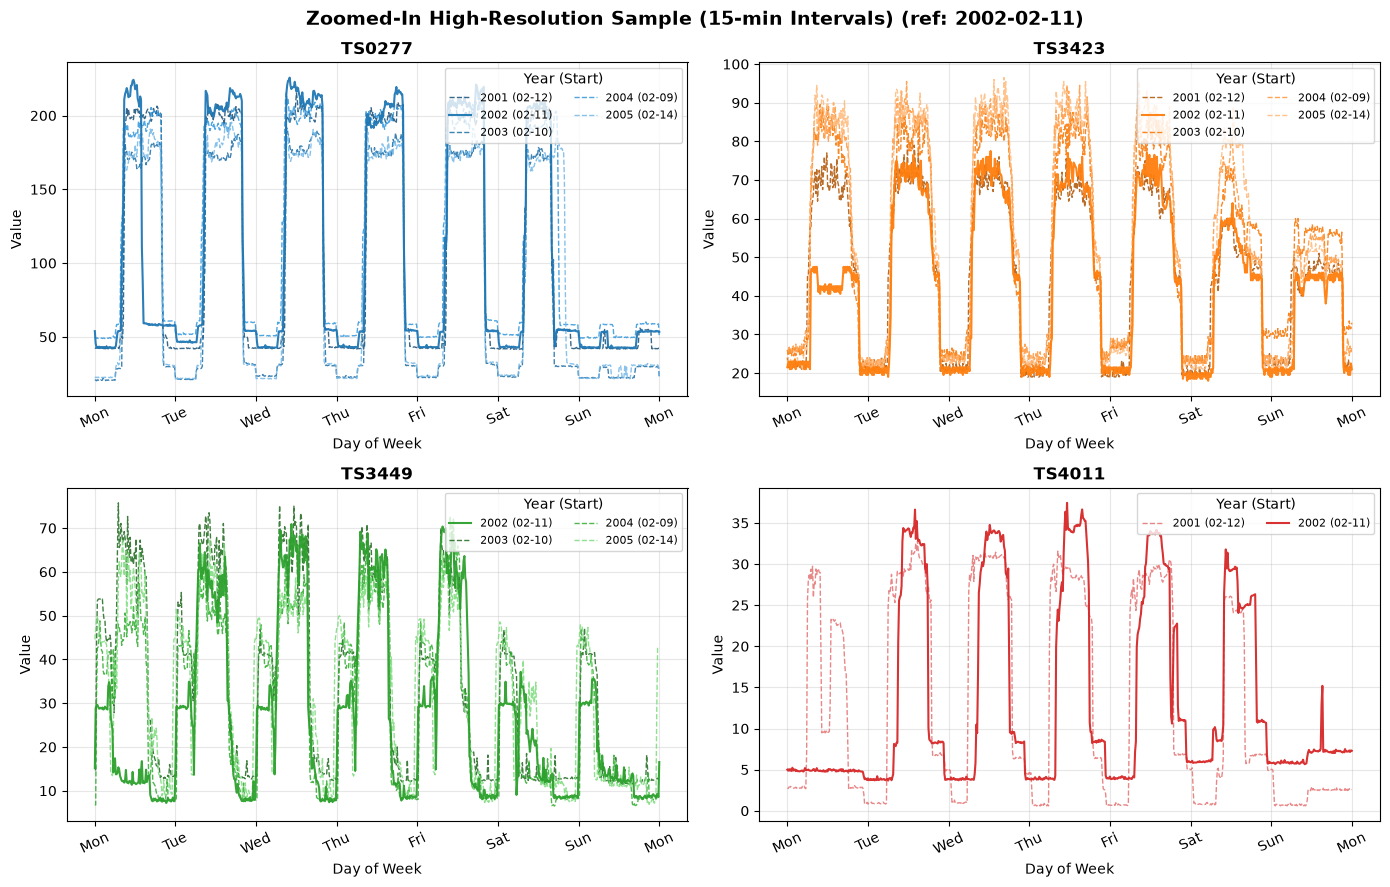

In [7]:
src.visualisations.zoom_datasets(datasets, yearly=True)

Examples of out-of-template cases - **movable holidays**:
- Rosenmontag (Carnival Monday, German public holiday) - `2002-02-11` - 48 days before Easter

**Fixed holidays** show the same Sunday-like drop across all four series:
- Easter Monday
- Labour Day (`2002-05-01`)
- German Unity Day (`2002-10-03`)

**Seasonality & Diurnal Cycle Notes:**
- The monthly aggregation isolates annual seasonality and any multi-year level drift without 15-minute noise obscuring the curve.
- Comparing weekday vs. weekend profiles reveals whether intraday peaks are driven by regular daily cycles or workweek schedules, while the 2-week July 2002 window shows local smoothness and volatility at full 15-minute resolution.